# Why Are Deliveries Late? — Part 1: Data Cleaning & First Look

**Business question:** DataCo, a global retailer, is seeing too many late deliveries. Where are the delays, what is driving them, and what should the business change?

**Data:** [DataCo Smart Supply Chain dataset](https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis) (Kaggle) — 180,519 order lines, Jan 2015 – Jan 2018.

**What this notebook does**
1. Loads the raw data and checks its quality
2. Cleans it — removes useless/sensitive columns, fixes dates, renames columns, translates country names
3. Creates new columns needed for the analysis (e.g. `days_late`, `is_late`)
4. Takes a first look at what drives late deliveries
5. Exports a clean file for SQL analysis (Part 2) and the Power BI dashboard (Part 3)

## 1. Load the data

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 60)   # show all columns instead of "..."

The file contains accented city/country names (e.g. *Rajastán*), so it is not saved as standard UTF-8.
Reading it without `encoding="latin-1"` fails with a `UnicodeDecodeError`.

In [2]:
raw = pd.read_csv("data/DataCoSupplyChainDataset.csv", encoding="latin-1")
raw.shape

(180519, 53)

In [3]:
raw.head(3)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class


**Important — what is one row?** Each row is one **product line within an order** (an "order item"), not one order.
An order with 3 different products appears as 3 rows. So the number of *orders* is much smaller than the number of rows:

In [4]:
print(f"Rows (order items): {len(raw):,}")
print(f"Unique orders:      {raw['Order Id'].nunique():,}")

Rows (order items): 180,519
Unique orders:      65,752


## 2. Data quality check
Before changing anything, check: data types, missing values, duplicate rows, duplicate columns, and columns that never change.

In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [6]:
missing = raw.isnull().sum()
missing[missing > 0]

Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519
dtype: int64

In [7]:
print("Duplicate rows:", raw.duplicated().sum())

Duplicate rows: 0


Some columns look like they hold the same information under different names. Check whether they are identical on every row:

In [8]:
pairs = [
    ("Order Customer Id", "Customer Id"),
    ("Benefit per order", "Order Profit Per Order"),
    ("Sales per customer", "Order Item Total"),
    ("Order Item Cardprod Id", "Product Card Id"),
    ("Product Category Id", "Category Id"),
    ("Product Price", "Order Item Product Price"),
]
for a, b in pairs:
    print(f"{a:25} == {b:25} -> {(raw[a] == raw[b]).all()}")

Order Customer Id         == Customer Id               -> True
Benefit per order         == Order Profit Per Order    -> True
Sales per customer        == Order Item Total          -> True
Order Item Cardprod Id    == Product Card Id           -> True
Product Category Id       == Category Id               -> True
Product Price             == Order Item Product Price  -> True


In [9]:
# Columns with only one value carry no information
n_unique = raw.nunique()
n_unique[n_unique == 1]

Customer Email       1
Customer Password    1
Product Status       1
dtype: int64

**Findings**
| Issue | Columns | Action |
|---|---|---|
| Completely / mostly empty | `Product Description` (100%), `Order Zipcode` (86%) | Drop — too empty to fill without inventing data |
| Masked, no information | `Customer Email`, `Customer Password` (all `XXXXXXXXX`) | Drop |
| Personal data not needed for analysis | first name, last name, street | Drop (data minimisation) |
| Exact duplicate columns | 6 pairs above | Drop one of each pair |
| Never changes | `Product Status` (always 0) | Drop |
| Dates stored as text | `order date`, `shipping date` | Convert to real dates |
| No duplicate rows | — | Nothing to do |

## 3. Cleaning

### 3.1 Drop columns we don't need

In [10]:
cols_to_drop = [
    "Product Description", "Order Zipcode",                    # empty / mostly empty
    "Customer Email", "Customer Password",                      # masked
    "Customer Fname", "Customer Lname", "Customer Street",      # personal data, not needed
    "Customer Zipcode", "Product Image",                         # not needed for this analysis
    "Order Customer Id", "Benefit per order", "Sales per customer",   # duplicates
    "Order Item Cardprod Id", "Product Category Id", "Product Price",
    "Product Status",                                            # constant
]
df = raw.drop(columns=cols_to_drop)
df.shape

(180519, 37)

### 3.2 Convert text dates to real dates

In [11]:
date_format = "%m/%d/%Y %H:%M"   # e.g. 1/31/2018 22:56  ->  month/day/year hour:minute
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"], format=date_format)
df["shipping_date"] = pd.to_datetime(df["shipping date (DateOrders)"], format=date_format)
df = df.drop(columns=["order date (DateOrders)", "shipping date (DateOrders)"])

df[["order_date", "shipping_date"]].agg(["min", "max"])

,order_date,shipping_date
min,2015-01-01 00:00:00,2015-01-03 00:00:00
max,2018-01-31 23:38:00,2018-02-06 22:14:00


### 3.3 Rename columns to `snake_case`
Names like `Days for shipping (real)` contain spaces and brackets, which are awkward in SQL (`"Days for shipping (real)"` must be quoted every time).
Short lowercase names with underscores are the standard.

In [12]:
rename_map = {
    "Type": "payment_type",
    "Days for shipping (real)": "days_shipping_actual",
    "Days for shipment (scheduled)": "days_shipping_scheduled",
    "Delivery Status": "delivery_status",
    "Late_delivery_risk": "late_delivery_risk",
    "Category Id": "category_id",
    "Category Name": "category_name",
    "Customer City": "customer_city",
    "Customer Country": "customer_country",
    "Customer Id": "customer_id",
    "Customer Segment": "customer_segment",
    "Customer State": "customer_state",
    "Department Id": "department_id",
    "Department Name": "department_name",
    "Latitude": "store_latitude",
    "Longitude": "store_longitude",
    "Market": "market",
    "Order City": "order_city",
    "Order Country": "order_country",
    "Order Id": "order_id",
    "Order Item Discount": "item_discount",
    "Order Item Discount Rate": "item_discount_rate",
    "Order Item Id": "order_item_id",
    "Order Item Product Price": "item_price",
    "Order Item Profit Ratio": "item_profit_ratio",
    "Order Item Quantity": "item_quantity",
    "Sales": "item_sales_gross",
    "Order Item Total": "item_sales_net",
    "Order Profit Per Order": "item_profit",
    "Order Region": "order_region",
    "Order State": "order_state",
    "Order Status": "order_status",
    "Product Card Id": "product_id",
    "Product Name": "product_name",
    "Shipping Mode": "shipping_mode",
}
df = df.rename(columns=rename_map)

# Safety check: every column should now be lowercase with no spaces
assert all(c == c.lower() and " " not in c for c in df.columns)
list(df.columns)

['payment_type',
 'days_shipping_actual',
 'days_shipping_scheduled',
 'delivery_status',
 'late_delivery_risk',
 'category_id',
 'category_name',
 'customer_city',
 'customer_country',
 'customer_id',
 'customer_segment',
 'customer_state',
 'department_id',
 'department_name',
 'store_latitude',
 'store_longitude',
 'market',
 'order_city',
 'order_country',
 'order_id',
 'item_discount',
 'item_discount_rate',
 'order_item_id',
 'item_price',
 'item_profit_ratio',
 'item_quantity',
 'item_sales_gross',
 'item_sales_net',
 'item_profit',
 'order_region',
 'order_state',
 'order_status',
 'product_id',
 'product_name',
 'shipping_mode',
 'order_date',
 'shipping_date']

### 3.4 Translate country names to English
Destination countries are stored in Spanish (`Reino Unido`, `Alemania`, …). Power BI's map visual needs English names,
and English is clearer for a UK audience. A lookup table in `reference/country_names_es_en.csv` maps all 164 names.

In [13]:
countries = pd.read_csv("reference/country_names_es_en.csv")
country_lookup = dict(zip(countries["country_es"], countries["country_en"]))

unmapped = set(df["order_country"]) - set(country_lookup)
assert not unmapped, f"Missing translations: {unmapped}"   # stops here if any country is missing

df["order_country"] = df["order_country"].map(country_lookup)
df["customer_country"] = df["customer_country"].replace({"EE. UU.": "United States"})

df["order_country"].value_counts().head(10)

order_country
United States     24840
France            13222
Mexico            13172
Germany            9564
Australia          8497
Brazil             7987
United Kingdom     7302
China              5758
Italy              4989
India              4783
Name: count, dtype: int64

## 4. New columns for the analysis

| New column | Meaning |
|---|---|
| `days_late` | actual − promised shipping days. Positive = late, 0 = on time, negative = early |
| `is_cancelled` | the shipment was cancelled (so it can't be on time or late) |
| `is_late` | 1 = late, 0 = not late, **empty for cancelled orders** |
| `order_month` | first day of the order's month — for monthly trends |

In [14]:
df["days_late"] = df["days_shipping_actual"] - df["days_shipping_scheduled"]
df["is_cancelled"] = df["delivery_status"] == "Shipping canceled"
df["is_late"] = (df["days_late"] > 0).astype("Int64").where(~df["is_cancelled"])
df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

df[["delivery_status", "days_shipping_scheduled", "days_shipping_actual", "days_late", "is_late"]].head()

,delivery_status,days_shipping_scheduled,days_shipping_actual,days_late,is_late
0,Advance shipping,4,3,-1,0
1,Late delivery,4,5,1,1
2,Shipping on time,4,4,0,0
3,Advance shipping,4,3,-1,0
4,Advance shipping,4,2,-2,0


**Why make `is_late` empty for cancelled orders?** The original `late_delivery_risk` column marks every cancelled shipment as 0 ("not late"),
so cancelled orders would count as successful deliveries and pull the late rate down. A cancelled order was never delivered,
so it should be left out of the on-time calculation altogether.
Check: for every *non-cancelled* row, our `is_late` should match the original column exactly — and no cancelled row is flagged late.

In [15]:
active = ~df["is_cancelled"]
print("Matches original for non-cancelled rows:",
      (df.loc[active, "is_late"] == df.loc[active, "late_delivery_risk"]).all())
print("Cancelled rows the original flagged as late:",
      int(df.loc[df["is_cancelled"], "late_delivery_risk"].sum()))

df = df.drop(columns=["late_delivery_risk"])   # replaced by is_late

Matches original for non-cancelled rows: True
Cancelled rows the original flagged as late: 0


## 5. First look — what is driving late deliveries?

Shipping details (mode, status, days) are the same for every item in an order, so to count **orders** correctly
we keep one row per order. (Counting rows would give orders with many items more weight.)

In [16]:
order_cols = ["order_id", "order_date", "order_month", "shipping_mode", "market", "order_region",
              "order_country", "customer_segment", "delivery_status", "days_shipping_scheduled",
              "days_shipping_actual", "days_late", "is_cancelled", "is_late"]

# Confirm the shipping columns really are identical within each order
assert (df.groupby("order_id")[["shipping_mode", "delivery_status", "days_shipping_actual"]].nunique() == 1).all().all()

orders = df[order_cols].drop_duplicates("order_id")
shipped = orders[~orders["is_cancelled"]]

print(f"Orders:            {len(orders):,}")
print(f"Cancelled:         {orders['is_cancelled'].sum():,}")
print(f"Shipped orders:    {len(shipped):,}")
print(f"Late rate:         {shipped['is_late'].mean():.1%}")

Orders:            65,752
Cancelled:         2,855
Shipped orders:    62,897
Late rate:         57.3%


> **Headline:** 57.3% of shipped orders arrived late.
>
> (The quick 54.8% figure from `value_counts()` on the raw data was slightly off: it counted *items* instead of orders, and included cancelled shipments in the total.)

### 5.1 Late rate by shipping mode

In [17]:
by_mode = (shipped.groupby("shipping_mode")
           .agg(orders=("order_id", "count"),
                promised_days=("days_shipping_scheduled", "mean"),
                actual_days=("days_shipping_actual", "mean"),
                late_rate=("is_late", "mean"))
           .sort_values("late_rate", ascending=False))
by_mode.round(2)

,orders,promised_days,actual_days,late_rate
shipping_mode,,,,
First Class,9602,1.0,2.00,1.0
Second Class,12256,2.0,4.00,0.8
Same Day,3407,0.0,0.48,0.48
Standard Class,37632,4.0,3.99,0.4


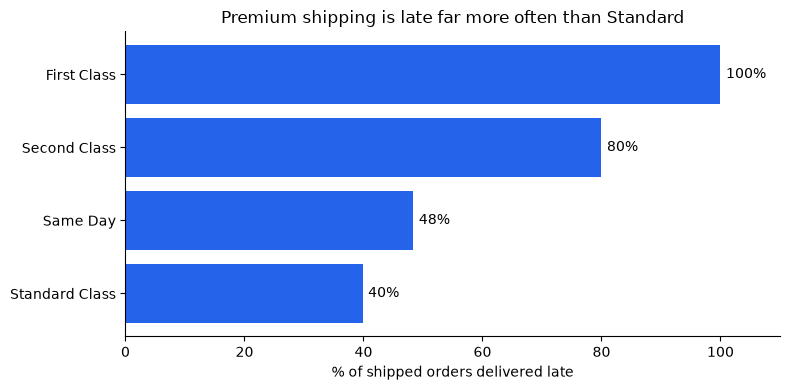

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(by_mode.index, by_mode["late_rate"] * 100, color="#2563eb")
ax.bar_label(bars, fmt="%.0f%%", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("% of shipped orders delivered late")
ax.set_title("Premium shipping is late far more often than Standard")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/late_rate_by_shipping_mode.png", dpi=150)
plt.show()

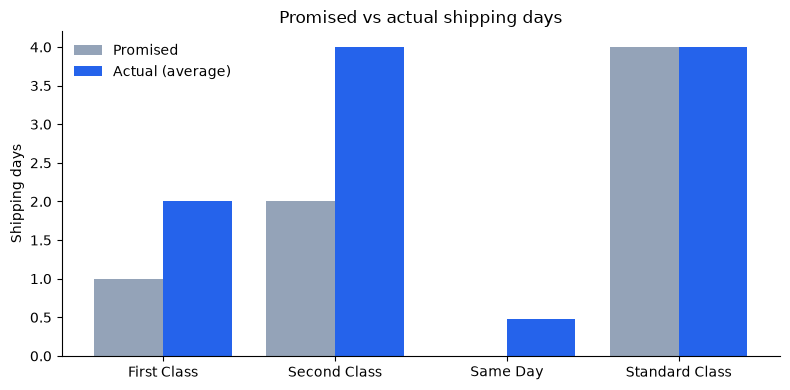

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(by_mode))
ax.bar([i - 0.2 for i in x], by_mode["promised_days"], width=0.4, label="Promised", color="#94a3b8")
ax.bar([i + 0.2 for i in x], by_mode["actual_days"], width=0.4, label="Actual (average)", color="#2563eb")
ax.set_xticks(list(x), by_mode.index)
ax.set_ylabel("Shipping days")
ax.set_title("Promised vs actual shipping days")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/promised_vs_actual_days.png", dpi=150)
plt.show()

**This is the key finding.** Each shipping mode has one fixed promise:

* **First Class** promises **1 day** but always takes **2** → **100% late**
* **Second Class** promises **2 days** but takes **~4** on average → **80% late**
* **Standard Class** promises **4 days** and takes **~4** → 40% late
* **Same Day** promises **0 days** → about half late

The premium services — the ones customers pay *more* for — are the ones that break their promise most.

### 5.2 Is it a geography or customer problem?

In [20]:
for col in ["market", "customer_segment"]:
    print(shipped.groupby(col)["is_late"].mean().mul(100).round(1).sort_values().to_string(), "\n")

market
Africa          56.5
LATAM           56.9
Europe          57.4
USCA            57.5
Pacific Asia    57.7 

customer_segment
Corporate      57.2
Consumer       57.3
Home Office    57.7 



The late rate is **~57% in every market and every customer segment**. Late delivery is not a regional or customer problem —
it is driven by **which shipping mode is used and what it promises**. This will be confirmed in detail with SQL in Part 2.

### 5.3 Data coverage check

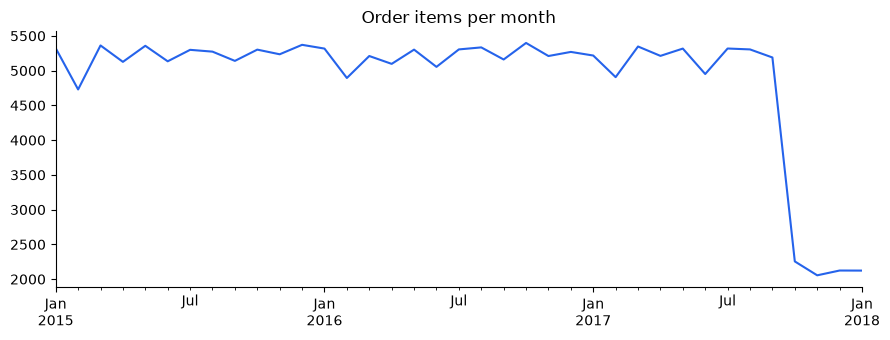

order_month
2017-08-01    5305
2017-09-01    5189
2017-10-01    2255
2017-11-01    2055
2017-12-01    2124
2018-01-01    2123
dtype: int64

In [21]:
monthly = df.groupby("order_month").size()
fig, ax = plt.subplots(figsize=(9, 3.5))
monthly.plot(ax=ax, color="#2563eb")
ax.set_title("Order items per month")
ax.set_xlabel("")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
monthly.tail(6)

⚠️ Volume drops by more than half from **October 2017** — likely incomplete data for the final months rather than a real fall in sales.
Trends over time should treat Oct 2017 – Jan 2018 with caution.

## 6. Export the clean data
* `data/clean_order_items.csv` — for the Power BI dashboard
* `data/supply_chain.db` — a SQLite database with one table, `order_items`, for the SQL analysis
* `data/powerbi_orders.csv` — one row per **order** (with order revenue and profit), so the Power BI measures stay simple

In [22]:
df.to_csv("data/clean_order_items.csv", index=False)

with sqlite3.connect("data/supply_chain.db") as conn:
    out = df.copy()
    for c in ["order_date", "shipping_date", "order_month"]:
        out[c] = out[c].dt.strftime("%Y-%m-%d %H:%M:%S")   # SQLite has no date type; ISO text sorts correctly
    out["is_cancelled"] = out["is_cancelled"].astype(int)
    out.to_sql("order_items", conn, if_exists="replace", index=False)
    print(pd.read_sql("SELECT COUNT(*) AS rows, COUNT(DISTINCT order_id) AS orders FROM order_items", conn))

df.shape

     rows  orders
0  180519   65752


(180519, 40)

In [23]:
# One row per order for Power BI: shipping fields are constant within an order, money is summed
order_money = df.groupby("order_id").agg(order_revenue=("item_sales_net", "sum"),
                                         order_profit=("item_profit", "sum"),
                                         items=("order_item_id", "count"))
powerbi = orders.merge(order_money, on="order_id")
powerbi["is_cancelled"] = powerbi["is_cancelled"].astype(int)
powerbi.to_csv("data/powerbi_orders.csv", index=False, date_format="%Y-%m-%d")
powerbi.shape

(65752, 17)

## 7. Summary

**Cleaning done**
* 180,519 order items (65,752 orders) — no duplicate rows
* Dropped 16 columns: empty, masked, personal, duplicated or constant
* Converted dates from text, renamed all columns to `snake_case`, translated 164 country names to English
* Added `days_late`, `is_cancelled`, `is_late` (excluding cancelled orders) and `order_month`

**First findings**
* **57.3%** of shipped orders were delivered late
* The cause is the **shipping mode's promise**, not geography or customer type: First Class is late 100% of the time, Second Class 80%
* Data for Oct 2017 – Jan 2018 looks incomplete

**Next:** Part 2 — answer the business questions in SQL using `data/supply_chain.db`.